# Part A (continued): Exploratory Data Analysis
**Project:** Food Safety and Restaurant Inspection Analytics &nbsp;|&nbsp; **Student:** Rushikesh Maddewad &nbsp;|&nbsp; PRN 202502040037 &nbsp;|&nbsp; Roll No 353

The EDA uses the curated file from `01_data_curation.ipynb`. Outcome analysis uses **completed inspections** only (Pass, Pass w/ Conditions, Fail), which is the grain of the warehouse fact table.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/curated/inspections_curated.csv", parse_dates=["inspection_date"], dtype={"zip": str})
comp = df[df["is_completed"]].copy()
print("Curated rows:", f"{len(df):,}", "| Completed inspections:", f"{len(comp):,}")

Curated rows: 73,601 | Completed inspections: 61,737


## A. Numerical analysis

In [2]:
def describe(series, name):
    s = series.dropna()
    q1, q3 = s.quantile([.25, .75])
    return pd.Series({"count": len(s), "mean": s.mean(), "median": s.median(), "min": s.min(), "max": s.max(),
                      "variance": s.var(), "std": s.std(), "Q1": q1, "Q3": q3, "IQR": q3 - q1,
                      "skewness": stats.skew(s), "kurtosis": stats.kurtosis(s)}, name=name)

per_facility = comp[comp["facility_id_source"] == "License"].groupby("facility_nk").size()
monthly = comp.groupby(comp["inspection_date"].dt.to_period("M")).size()
table = pd.concat([describe(comp["violation_count"], "ViolationCount (per inspection)"),
                   describe(per_facility, "Inspections per facility (2022-2025)"),
                   describe(monthly, "Inspections per month")], axis=1).T
table.round(2)

,count,mean,median,min,max,variance,std,Q1,Q3,IQR,skewness,kurtosis
ViolationCount (per inspection),61185.0,3.77,3.0,0.0,40.0,13.72,3.70,1.00,5.00,4.0,1.64,4.03
Inspections per facility (2022-2025),17001.0,3.62,3.0,1.0,25.0,5.83,2.41,2.00,5.00,3.0,1.22,3.18
Inspections per month,48.0,1286.19,1304.0,917.0,1641.0,29040.33,170.41,1156.25,1385.75,229.5,0.05,-0.27


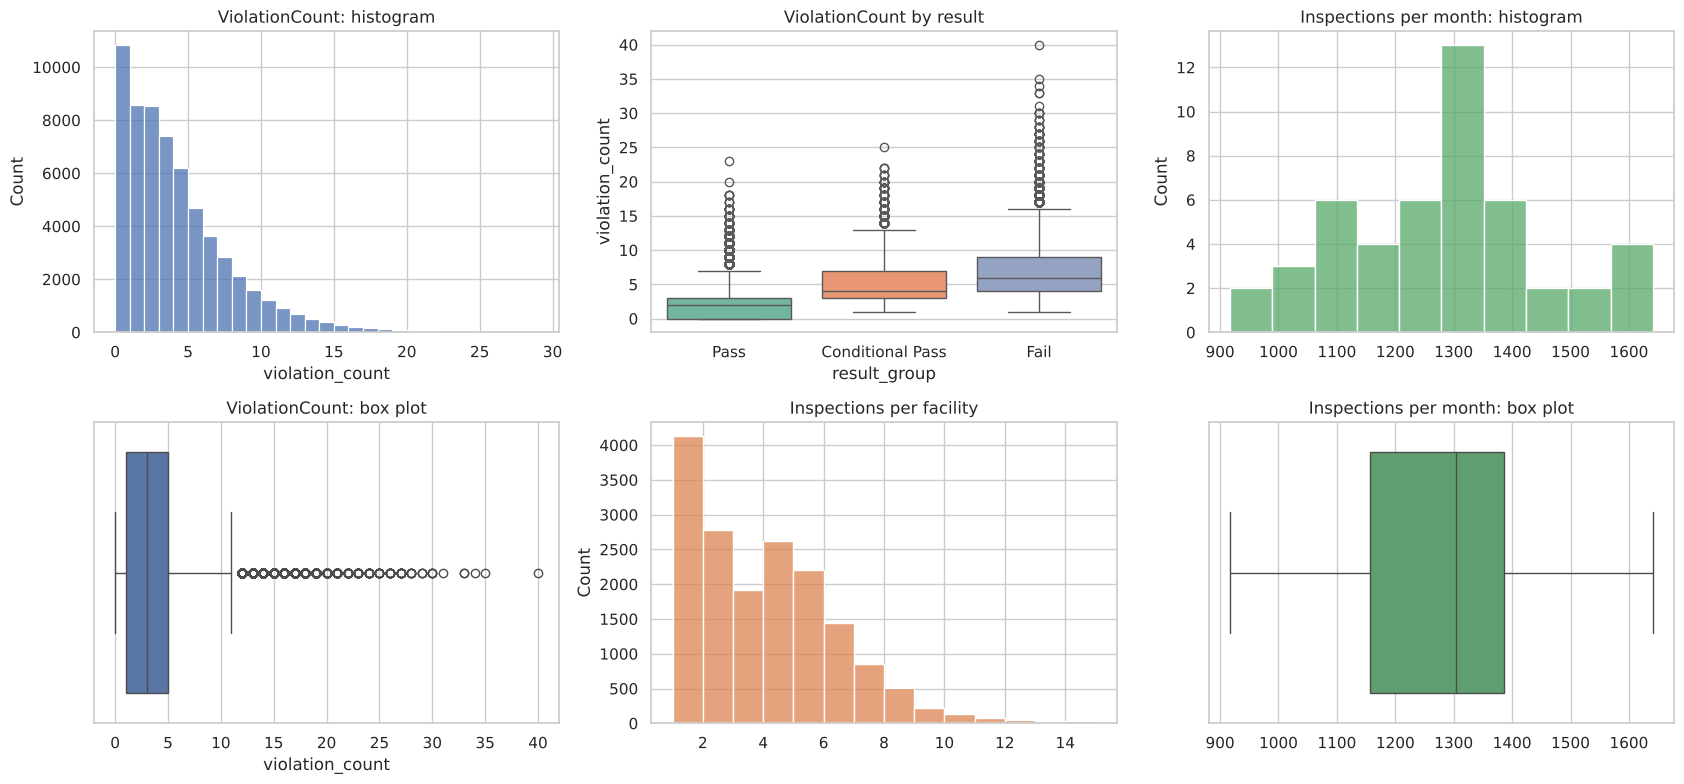

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
sns.histplot(comp["violation_count"].dropna(), bins=range(0, 30), ax=ax[0, 0], color="#4C72B0")
ax[0, 0].set_title("ViolationCount: histogram")
sns.boxplot(x=comp["violation_count"].dropna(), ax=ax[1, 0], color="#4C72B0")
ax[1, 0].set_title("ViolationCount: box plot")
sns.boxplot(data=comp, x="result_group", y="violation_count", order=["Pass", "Conditional Pass", "Fail"], hue="result_group", hue_order=["Pass", "Conditional Pass", "Fail"], legend=False, ax=ax[0, 1], palette="Set2")
ax[0, 1].set_title("ViolationCount by result")
sns.histplot(per_facility, bins=range(1, 16), ax=ax[1, 1], color="#DD8452")
ax[1, 1].set_title("Inspections per facility")
sns.histplot(monthly.values, bins=10, ax=ax[0, 2], color="#55A868")
ax[0, 2].set_title("Inspections per month: histogram")
sns.boxplot(x=monthly.values, ax=ax[1, 2], color="#55A868")
ax[1, 2].set_title("Inspections per month: box plot")
plt.tight_layout(); plt.show()

**Inference (numerical analysis):**
- **ViolationCount** (61,185 inspections with a known count): mean 3.77, median 3, Q1 = 1, Q3 = 5, IQR = 4, standard deviation 3.70, maximum 40. The skewness of 1.64 and kurtosis of 4.03 show a long right tail: most inspections cite 0-5 violations, but a few cite more than 20, and the mean is above the median. The box plot marks everything above 11 as an outlier; these inspections are kept (see the data-quality report).
- By result the count rises clearly: mean 2.25 for *Pass*, 5.16 for *Pass w/ Conditions* and 6.94 for *Fail*.
- **Inspections per facility** (17,001 facilities with a licence): mean 3.6, median 3, maximum 25 over the four years, so repeat visits are normal. The long tail comes from facilities that are re-inspected many times.
- **Inspections per month:** mean 1,286 and median 1,304, with a skewness near 0 (0.05), so the monthly volume is roughly symmetric (minimum 917, maximum 1,641) and no month is an outlier.

## B. Categorical analysis

In [4]:
def freq(col, data=df, top=None):
    f = data[col].value_counts(dropna=False).rename("count").to_frame()
    f["percent"] = (f["count"] / f["count"].sum() * 100).round(2)
    return f.head(top) if top else f

for col in ["result_group", "risk_group", "facility_group", "inspection_type_group"]:
    print(f"--- {col}"); display(freq(col))

ft = freq("facility_type_clean")
print("Top 10 raw-derived facility types:"); display(ft.head(10))
rare = ft[ft["percent"] < 0.1]
print(f"Rare facility types (< 0.1% of rows): {len(rare)} of {len(ft)} categories, together {rare['count'].sum()} rows ({rare['percent'].sum():.2f}%)")

--- result_group


,count,percent
result_group,,
Pass,37734,51.27
Fail,14260,19.37
Not Completed,11864,16.12
Conditional Pass,9743,13.24


--- risk_group


,count,percent
risk_group,,
High,59151,80.37
Medium,10869,14.77
Low,3526,4.79
Unknown,55,0.07


--- facility_group


,count,percent
facility_group,,
Restaurant & Food Service,52217,70.95
Schools & Childcare,9193,12.49
Retail Food & Grocery,8626,11.72
"Mobile, Catering & Events",1822,2.48
Healthcare & Residential Care,1404,1.91
Unknown,320,0.43
Other,19,0.03


--- inspection_type_group


,count,percent
inspection_type_group,,
Routine (Canvass),36278,49.29
Re-inspection,14629,19.88
License,9772,13.28
Complaint / Illness,8701,11.82
Other,4221,5.73


Top 10 raw-derived facility types:


,count,percent
facility_type_clean,,
Restaurant,51991,70.64
Grocery Store,7062,9.59
School,4608,6.26
Children's Services Facility,2628,3.57
Daycare Above And Under 2 Years,1104,1.50
Bakery,1013,1.38
Long Term Care,773,1.05
Catering,476,0.65
Daycare (2 - 6 Years),470,0.64


Rare facility types (< 0.1% of rows): 184 of 203 categories, together 1337 rows (1.74%)


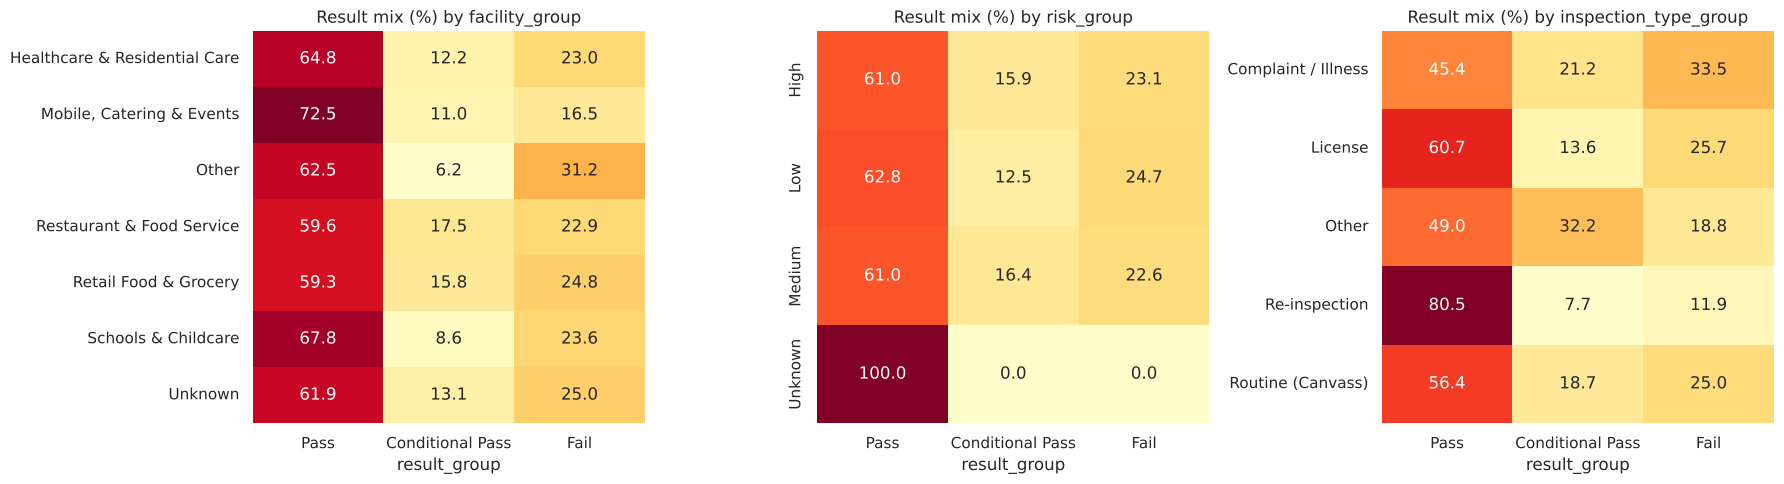

Counts behind the first heat map:


result_group,Conditional Pass,Fail,Pass,All
facility_group,,,,
Healthcare & Residential Care,159,299,843,1301
"Mobile, Catering & Events",167,249,1097,1513
Other,1,5,10,16
Restaurant & Food Service,7535,9878,25644,43057
Retail Food & Grocery,1129,1771,4229,7129
Schools & Childcare,741,2037,5859,8637
Unknown,11,21,52,84
All,9743,14260,37734,61737


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, col in zip(ax, ["facility_group", "risk_group", "inspection_type_group"]):
    ct = pd.crosstab(comp[col], comp["result_group"], normalize="index")[["Pass", "Conditional Pass", "Fail"]] * 100
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="YlOrRd", ax=a, cbar=False)
    a.set_title(f"Result mix (%) by {col}"); a.set_ylabel("")
plt.tight_layout(); plt.show()
print("Counts behind the first heat map:")
pd.crosstab(comp["facility_group"], comp["result_group"], margins=True)

**Inference (categorical analysis):**
- Of all 73,601 curated rows, 51.3% are *Pass*, 19.4% *Fail*, 13.2% *Conditional Pass* and 16.1% *Not Completed*. Among the 61,737 **completed** inspections the shares are 61.1% Pass, 15.8% Conditional Pass and 23.1% Fail.
- 80.4% of the inspections are of **high-risk** facilities and 71% are of restaurants (Restaurant & Food Service). Schools and childcare (12.5%) and retail food and grocery (11.7%) are the next groups.
- **Rare categories:** the raw facility type has 203 spellings, and 184 of them each cover less than 0.1% of the rows (1.74% of rows in total). This is why the derived FacilityGroup is needed for analysis.
- **Cross-tabulation with the result:** the fail share is similar across the big groups (retail 24.8%, schools 23.6%, healthcare and residential care 23.0%, restaurants 22.9%) and lowest for mobile, catering and events (16.5%).
- **Risk and result:** the result mix is almost the same for High (23.1% fail), Medium (22.6%) and Low risk (24.7%). The risk category tells us how often a place is inspected, but not how likely it is to fail on a given visit.
- **Inspection type:** complaint and illness inspections fail most often (33.5%), then licence (25.8%) and routine canvass (25.0%). **Re-inspections** fail least (11.9%), which suggests most businesses fix their problems after a failed visit.

## C. Temporal analysis

,inspections,fail_rate
year,,
2022,14281,24.88
2023,15412,24.88
2024,15992,21.77
2025,16052,21.13


quarter,1,2,3,4
year,,,,
2022,3091,3760,3807,3623
2023,3708,3906,3818,3980
2024,3715,4187,4054,4036
2025,4269,4246,3890,3647


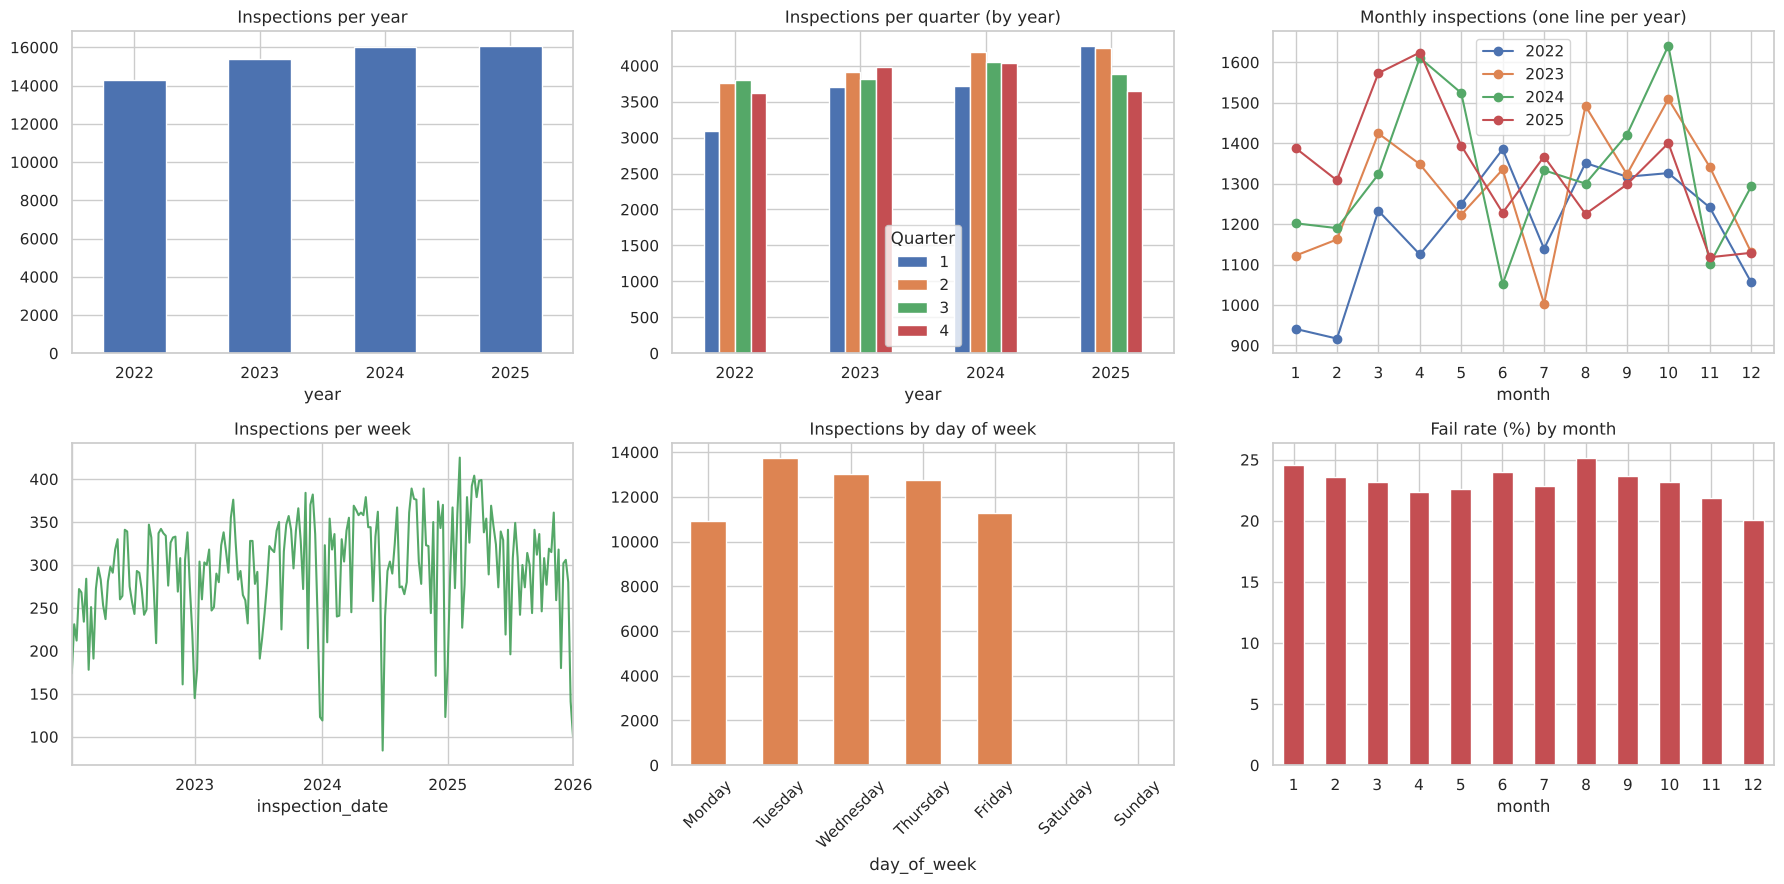

Busiest months : {Period('2024-10', 'M'): 1641, Period('2025-04', 'M'): 1624, Period('2024-04', 'M'): 1611}
Quietest months: {Period('2022-02', 'M'): 917, Period('2022-01', 'M'): 941, Period('2023-07', 'M'): 1003}
Hourly / time-band pattern: NOT AVAILABLE (every timestamp is 00:00:00 in the source).


In [6]:
yearly = comp.groupby("year").agg(inspections=("inspection_id", "size"), fail_rate=("is_failed_inspection", "mean"))
yearly["fail_rate"] = (yearly["fail_rate"] * 100).round(2)
quarterly = comp.groupby(["year", "quarter"]).size().unstack()
display(yearly); display(quarterly)

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
yearly["inspections"].plot(kind="bar", ax=ax[0, 0], color="#4C72B0"); ax[0, 0].set_title("Inspections per year"); ax[0, 0].tick_params(axis="x", rotation=0)
quarterly.plot(kind="bar", ax=ax[0, 1]); ax[0, 1].set_title("Inspections per quarter (by year)"); ax[0, 1].tick_params(axis="x", rotation=0); ax[0, 1].legend(title="Quarter")
for y, g in comp.groupby("year"):
    g.groupby("month").size().plot(ax=ax[0, 2], marker="o", label=str(y))
ax[0, 2].set_title("Monthly inspections (one line per year)"); ax[0, 2].set_xticks(range(1, 13)); ax[0, 2].legend()
weekly = comp.set_index("inspection_date").resample("W").size()
weekly.plot(ax=ax[1, 0], color="#55A868"); ax[1, 0].set_title("Inspections per week")
dow = comp["day_of_week"].value_counts().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
dow.plot(kind="bar", ax=ax[1, 1], color="#DD8452"); ax[1, 1].set_title("Inspections by day of week"); ax[1, 1].tick_params(axis="x", rotation=45)
comp.groupby("month")["is_failed_inspection"].mean().mul(100).plot(kind="bar", ax=ax[1, 2], color="#C44E52")
ax[1, 2].set_title("Fail rate (%) by month"); ax[1, 2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

by_month = comp.groupby(comp["inspection_date"].dt.to_period("M")).size()
print("Busiest months :", by_month.nlargest(3).to_dict())
print("Quietest months:", by_month.nsmallest(3).to_dict())
print("Hourly / time-band pattern: NOT AVAILABLE (every timestamp is 00:00:00 in the source).")

**Inference (temporal analysis):**
- **Yearly:** completed inspections grew from 14,281 (2022) to 15,412 (2023), 15,992 (2024) and 16,052 (2025), about 12% more in four years. The fail rate fell from 24.9% (2022 and 2023) to 21.8% (2024) and 21.1% (2025).
- **Quarterly:** Q1 2022 was the quietest quarter (3,091) and Q1 2025 the busiest (4,269). The busiest quarter changes every year (Q3 in 2022, Q4 in 2023, Q2 in 2024, Q1 in 2025), so there is no stable seasonal peak.
- **Monthly:** the busiest months were October 2024 (1,641), April 2025 (1,624) and April 2024 (1,611). The quietest were February 2022 (917), January 2022 (941) and July 2023 (1,003).
- **Day of week:** inspections happen on weekdays; Tuesday (13,725) and Wednesday (13,019) are busiest and Monday (10,936) the quietest weekday. Only 5 completed inspections took place on a Saturday and none on a Sunday.
- **Season:** the fail rate is highest in August (25.1%), January (24.5%) and June (24.0%) and lowest in December (20.1%) and November (21.8%).
- **Hourly pattern:** not available, because the source has no time of day.

## D. Geographic analysis

In [7]:
geo_ok = comp["latitude"].notna()
print("Coordinates available for %.2f%% of completed inspections; none lie outside the Chicago bounding box (validated in curation)." % (geo_ok.mean() * 100))

area = comp.groupby("geographic_area_group").agg(inspections=("inspection_id", "size"), fail_rate=("is_failed_inspection", "mean"))
area["fail_rate"] = (area["fail_rate"] * 100).round(2)
display(area)

zip_t = comp[comp["zip"] != "Unknown"].groupby("zip").agg(inspections=("inspection_id", "size"), fails=("is_failed_inspection", "sum"))
zip_t["fail_rate"] = (zip_t["fails"] / zip_t["inspections"] * 100).round(2)
big = zip_t[zip_t["inspections"] >= 200]
print("Top 8 ZIP codes by NUMBER of inspections:");   display(zip_t.nlargest(8, "inspections"))
print("Top 8 ZIP codes by FAIL RATE (at least 200 inspections):"); display(big.nlargest(8, "fail_rate"))

Coordinates available for 99.62% of completed inspections; none lie outside the Chicago bounding box (validated in curation).


,inspections,fail_rate
geographic_area_group,,
Northeast,2906,18.93
Northwest,32608,21.80
Southeast,7963,26.71
Southwest,18028,24.56
Unknown,232,19.40


Top 8 ZIP codes by NUMBER of inspections:


,inspections,fails,fail_rate
zip,,,
60647,2361,508,21.52
60614,2227,543,24.38
60611,2078,420,20.21
60622,2031,515,25.36
60607,1991,423,21.25
60618,1973,351,17.79
60608,1967,536,27.25
60616,1940,516,26.60


Top 8 ZIP codes by FAIL RATE (at least 200 inspections):


,inspections,fails,fail_rate
zip,,,
60617,1403,526,37.49
60620,1179,394,33.42
60628,1077,349,32.40
60619,1220,378,30.98
60636,687,210,30.57
60651,836,251,30.02
60621,438,131,29.91
60639,1701,508,29.86


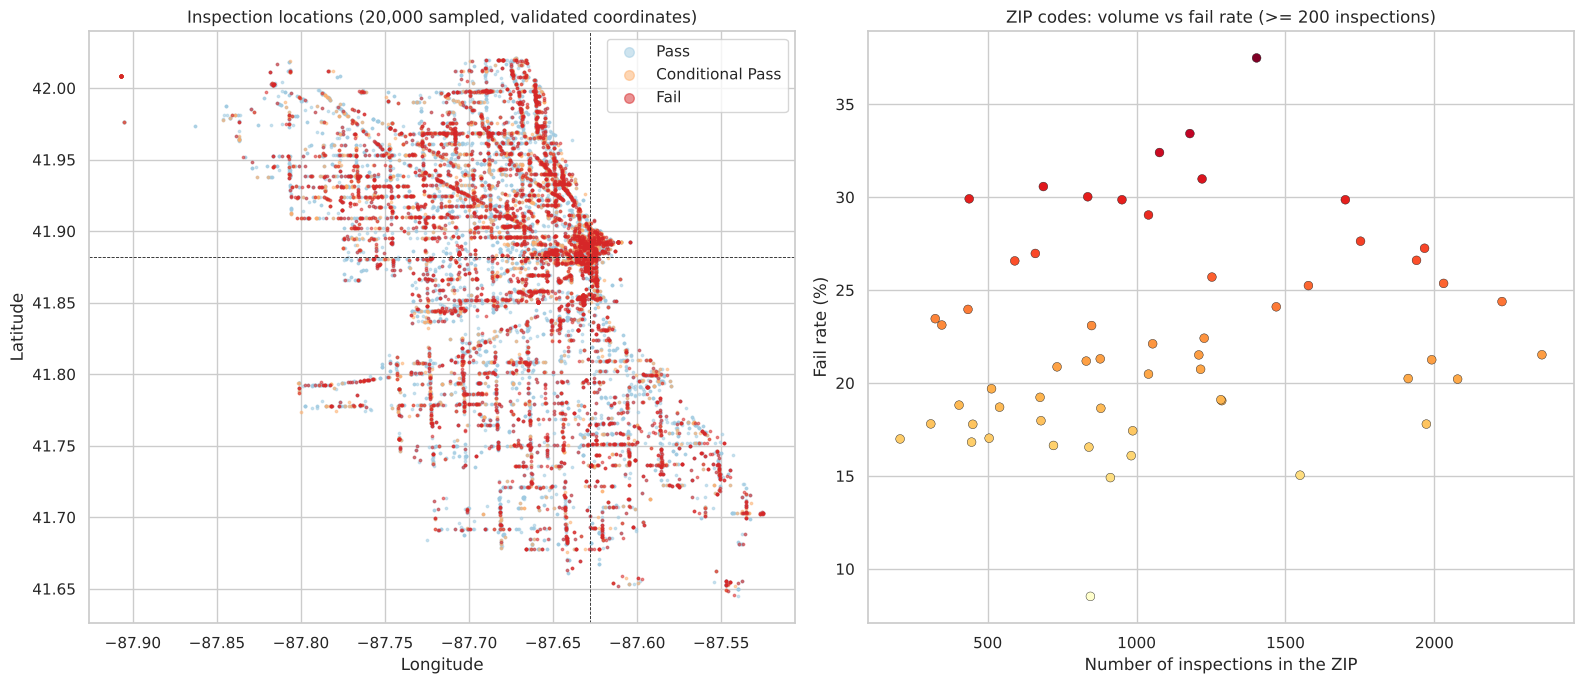

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
s = comp[geo_ok].sample(min(20000, geo_ok.sum()), random_state=1)
for res, colour in [("Pass", "#9ecae1"), ("Conditional Pass", "#fdae6b"), ("Fail", "#d62728")]:
    g = s[s["result_group"] == res]
    ax[0].scatter(g["longitude"], g["latitude"], s=3, alpha=0.5, c=colour, label=res)
ax[0].set_title("Inspection locations (20,000 sampled, validated coordinates)"); ax[0].set_xlabel("Longitude"); ax[0].set_ylabel("Latitude"); ax[0].legend(markerscale=4)
ax[0].axhline(41.8820, color="k", lw=0.6, ls="--"); ax[0].axvline(-87.6278, color="k", lw=0.6, ls="--")
sc = ax[1].scatter(big["inspections"], big["fail_rate"], s=40, c=big["fail_rate"], cmap="YlOrRd", edgecolor="k", linewidth=0.3)
ax[1].set_xlabel("Number of inspections in the ZIP"); ax[1].set_ylabel("Fail rate (%)"); ax[1].set_title("ZIP codes: volume vs fail rate (>= 200 inspections)")
plt.tight_layout(); plt.show()

**Inference (geographic analysis):**
- Coordinates exist for 99.62% of the completed inspections and all of them lie inside the Chicago box. The scatter plot draws the shape of the city and the street grid, which is a good visual check that the coordinates are valid. The dashed lines mark the origin of the street grid (State and Madison) used for the area groups.
- **Area groups:** the failure rate is highest in the Southeast (26.7%) and Southwest (24.6%) and lower in the Northwest (21.8%) and Northeast (18.9%).
- **Volume is not rate:** the ZIP codes with the most inspections (60647: 2,361, 60614: 2,227, 60611: 2,078) have fail rates between 20% and 24%. The highest fail rates are in 60617 (37.5%), 60620 (33.4%) and 60628 (32.4%), all ZIPs with fewer inspections. For example 60618 is 6th by volume but has the lowest fail rate (17.8%) of the eight busiest ZIP codes. Ranking areas by raw totals would point to the wrong places.
- The right-hand scatter plot shows that the fail rate does not depend on volume: high rates occur at both small and large volumes.

## E. Outcome / performance analysis (volume versus rate)

,inspections,fails,conditional,avg_violations,fail_rate_%,conditional_rate_%
facility_group,,,,,,
Restaurant & Food Service,43057,9878,7535,4.06,22.94,17.50
Schools & Childcare,8637,2037,741,2.44,23.58,8.58
Retail Food & Grocery,7129,1771,1129,4.14,24.84,15.84
"Mobile, Catering & Events",1513,249,167,2.14,16.46,11.04
Healthcare & Residential Care,1301,299,159,3.30,22.98,12.22
Unknown,84,21,11,2.79,25.00,13.10
Other,16,5,1,2.33,31.25,6.25


,inspections,fail_rate
inspection_type_group,,
Complaint / Illness,8121,33.47
License,8102,25.75
Routine (Canvass),30875,24.96
Other,149,18.79
Re-inspection,14490,11.88


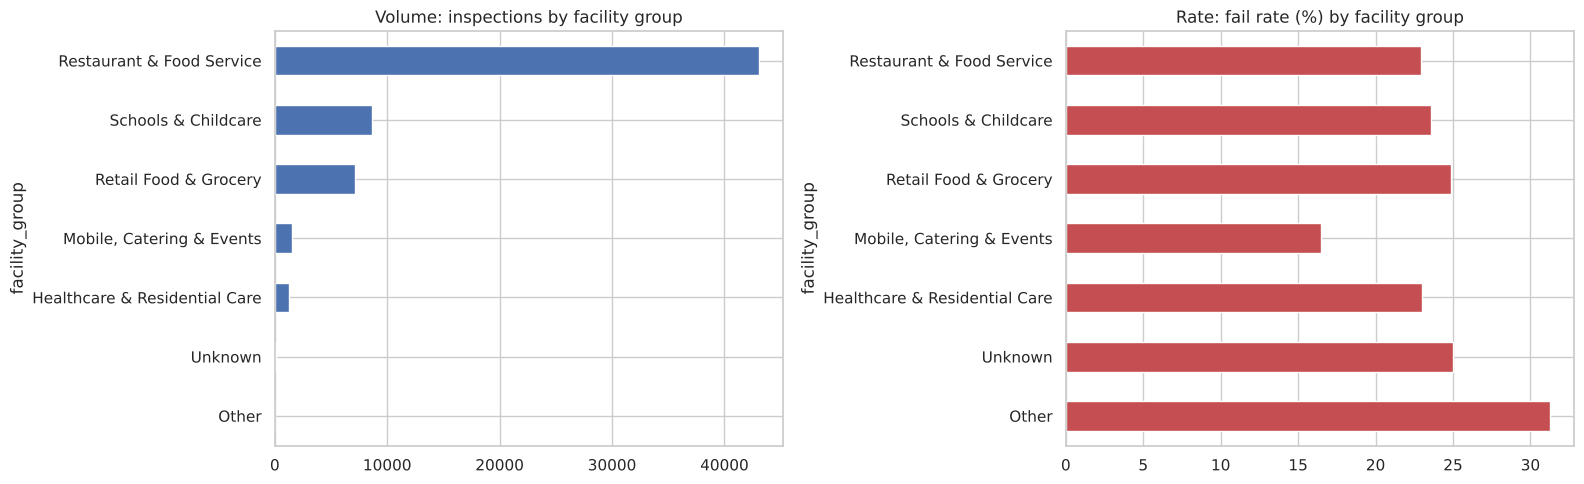

In [9]:
fg = comp.groupby("facility_group").agg(inspections=("inspection_id", "size"), fails=("is_failed_inspection", "sum"),
                                         conditional=("result_group", lambda s: (s == "Conditional Pass").sum()),
                                         avg_violations=("violation_count", "mean"))
fg["fail_rate_%"] = (fg["fails"] / fg["inspections"] * 100).round(2)
fg["conditional_rate_%"] = (fg["conditional"] / fg["inspections"] * 100).round(2)
fg["avg_violations"] = fg["avg_violations"].round(2)
fg = fg.sort_values("inspections", ascending=False)
display(fg)

it = comp.groupby("inspection_type_group").agg(inspections=("inspection_id", "size"), fail_rate=("is_failed_inspection", "mean"))
it["fail_rate"] = (it["fail_rate"] * 100).round(2)
display(it.sort_values("fail_rate", ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
fg["inspections"].plot(kind="barh", ax=ax[0], color="#4C72B0"); ax[0].set_title("Volume: inspections by facility group"); ax[0].invert_yaxis()
fg["fail_rate_%"].plot(kind="barh", ax=ax[1], color="#C44E52"); ax[1].set_title("Rate: fail rate (%) by facility group"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

**Inference (outcome analysis, volume versus rate):**
- **Restaurants** make up 70% of all completed inspections and 69% of all failures (9,878 of 14,260), but their fail rate of 22.9% is close to the overall 23.1%. They are the biggest in volume, not the worst in rate.
- **Retail food and grocery** has the highest fail rate among the large groups (24.8%) and the highest average violation count (4.14).
- **Schools and childcare** fail 23.6% of the time with a low average violation count (2.44) and a low conditional-pass rate (8.6%), which means a school usually fails because of a few serious findings and not because of many small ones.
- **Mobile, catering and events** has the lowest fail rate (16.5%), but it has only 1,513 inspections.
- By inspection type, a complaint or illness inspection is almost three times as likely to fail as a re-inspection (33.5% vs 11.9%).
- The comparison of the two bar charts shows why both counts and rates are needed: the order of the groups is different in the volume chart and in the rate chart.